# TP8 - Classification Multiclasse avec CNN et Transfer Learning

**Pr. I. HAMZAOUI**
## Dataset: tf_flowers

---
# PARTIE I : Pipeline CNN pour classification multiclasse
---

## Q1) Import des bibliothèques et chargement du dataset

In [6]:
# Q1) IMPORTATION DES BIBLIOTHÈQUES

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report



In [7]:
# CHARGEMENT DU DATASET

dataset, info = tfds.load("tf_flowers", with_info=True, as_supervised=True)
data = dataset["train"]

print("Nombre total d'images :", info.splits["train"].num_examples)
print("Noms des classes :", info.features["label"].names)

Nombre total d'images : 3670
Noms des classes : ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


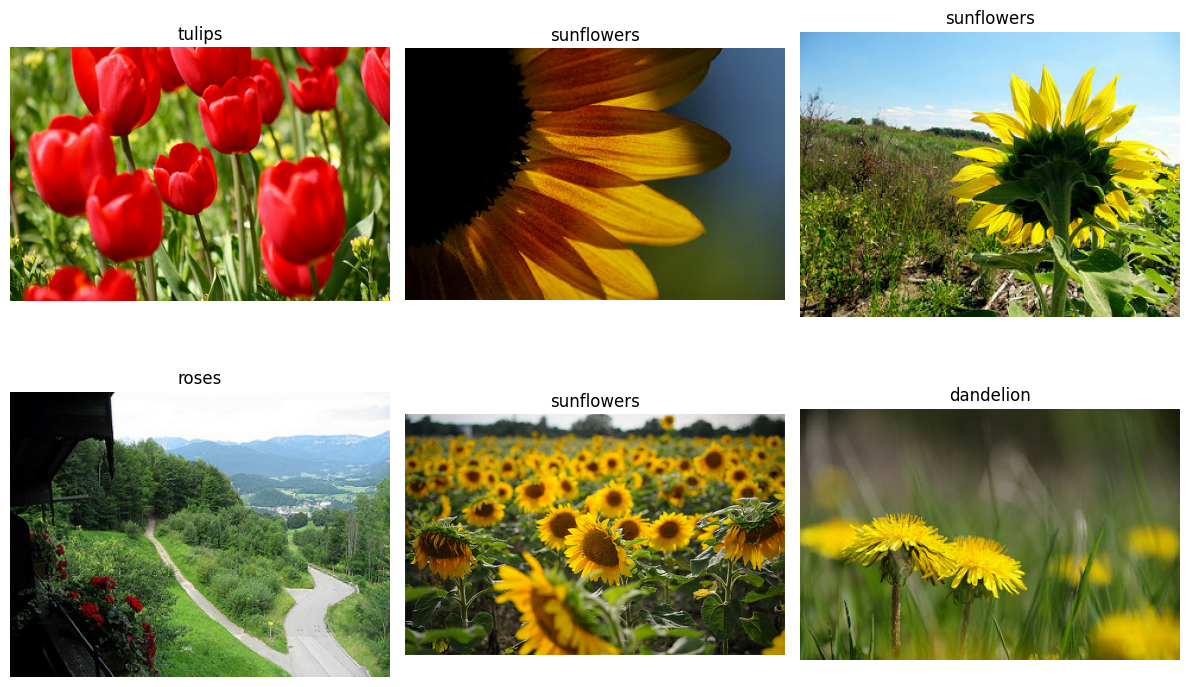

In [8]:
# VISUALISATION DE QUELQUES IMAGES BRUTES

class_names = info.features["label"].names

plt.figure(figsize=(12, 8))
for i, (image, label) in enumerate(data.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Q2) Observation des dimensions

In [9]:
print("Shapes de quelques images:\n")
for i, (image, label) in enumerate(data.take(10)):
    print(f"Image {i+1}: {image.shape}")

Shapes de quelques images:

Image 1: (333, 500, 3)
Image 2: (212, 320, 3)
Image 3: (240, 320, 3)
Image 4: (240, 320, 3)
Image 5: (317, 500, 3)
Image 6: (212, 320, 3)
Image 7: (240, 240, 3)
Image 8: (333, 500, 3)
Image 9: (240, 320, 3)
Image 10: (240, 320, 3)


### Réponse Q2:

**Observation:** Les images ont des dimensions variables (hauteur et largeur différentes).

**Importance:**
- Les CNN nécessitent des entrées de taille fixe
- L'architecture du modèle est définie avec des dimensions spécifiques
- Pour le traitement en batch, toutes les images doivent avoir la même forme

**Solution:** >>>Redimensionner toutes les images à 128×128 lors du prétraitement.

## Q3) Conversion en NumPy

In [10]:
# Conversion en NumPy arrays

images = []
labels = []

for image, label in data:
    images.append(image.numpy())
    labels.append(label.numpy())

images = np.array(images, dtype=object)
labels = np.array(labels)

print(f"Nombre d'images: {len(images)}")
print(f"Nombre de labels : {len(labels)}")

Nombre d'images: 3670
Nombre de labels : 3670


### Réponse Q3:

**Pourquoi cette transformation:**
- Flexibilité de manipulation avec NumPy
- Compatibilité avec scikit-learn (train_test_split)
- Facilite le prétraitement (normalisation, redimensionnement)
- Interface standard pour les données numériques en Python

## Q4) Redimensionnement et normalisation

In [11]:
# 4) REDIMENSIONNEMENT ET NORMALISATION

processed_images = []

for image in images:
    # Redimensionner à 128x128
    image_resized = tf.image.resize(image, (128, 128))
    # Convertir en float32 puis normaliser
    image_resized = tf.cast(image_resized, tf.float32) / 255.0
    processed_images.append(image_resized.numpy())

processed_images = np.array(processed_images)

print("Shape après prétraitement :", processed_images.shape)
print("Shape d'une image :", processed_images[0].shape)
print("Valeur min :", processed_images[0].min())
print("Valeur max :", processed_images[0].max())

Shape après prétraitement : (3670, 128, 128, 3)
Shape d'une image : (128, 128, 3)
Valeur min : 0.0
Valeur max : 1.0


### Réponse Q4:

**Pourquoi convertir en float32 avant normalisation:**

- Les pixels bruts sont en uint8 (0-255)
- Division par 255 → résultats décimaux [0, 1]
- Si on reste en uint8: 128/255 = 0 (perte totale)
- float32 permet la précision décimale nécessaire aux gradients

**Si on restait en int/uint:**
- Division entière → toutes valeurs = 0 ou 1
- Perte de toutes les nuances de couleur
- Impossible d'entraîner le modèle

## Q5) Découpage des données

In [12]:
# Train (70%), validation (15%), test (15%)

X_train, X_temp, y_train, y_temp = train_test_split(
    processed_images, labels, test_size=0.30, random_state=42, stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape}, {y_train.shape}")
print(f"Validation: {X_val.shape}, {y_val.shape}")
print(f"Test: {X_test.shape}, {y_test.shape}")

total = len(processed_images)
print(f"\nTrain: {len(X_train)/total*100:.1f}%")
print(f"Val: {len(X_val)/total*100:.1f}%")
print(f"Test: {len(X_test)/total*100:.1f}%")

Train: (2569, 128, 128, 3), (2569,)
Validation: (550, 128, 128, 3), (550,)
Test: (551, 128, 128, 3), (551,)

Train: 70.0%
Val: 15.0%
Test: 15.0%


## Q6) Data Augmentation

In [13]:
# 6) DATA AUGMENTATION

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

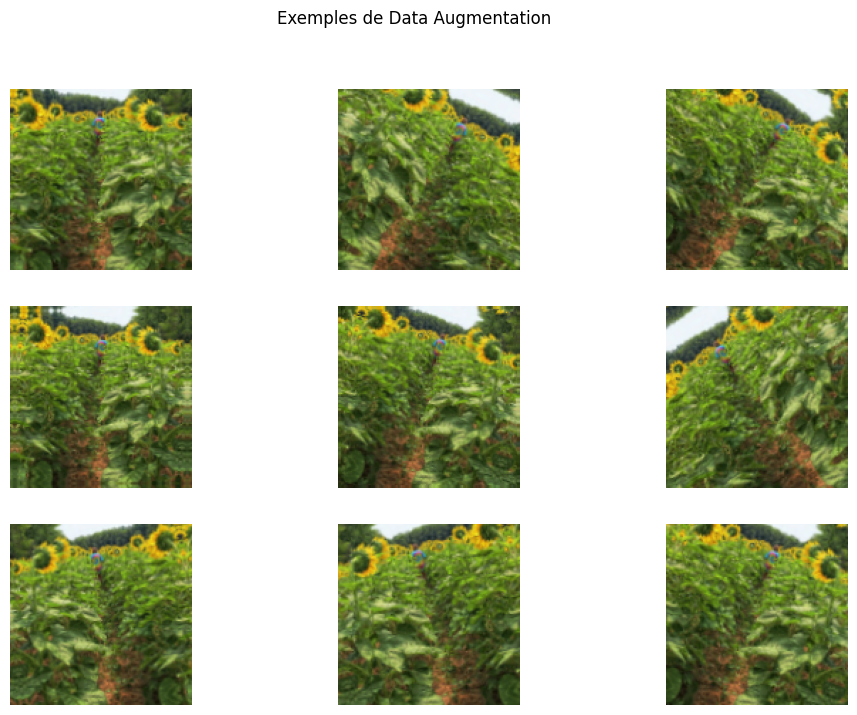

In [14]:
# Visualisation

plt.figure(figsize=(12, 8))
sample = X_train[0:1]

for i in range(9):
    augmented = data_augmentation(sample, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented[0])
    plt.axis('off')
plt.suptitle("Exemples de Data Augmentation")
plt.show()

### Réponse Q6:

**Rôle de chaque transformation:**

- **RandomFlip:** Retourne l'image horizontalement (fleur reste reconnaissable)
- **RandomRotation(0.1):** Rotation jusqu'à ±36° (photos sous différents angles)
- **RandomZoom(0.1):** Zoom in/out 10% (différentes distances)

**Intérêt:**
- Augmente virtuellement le dataset
- Réduit l'overfitting (modèle ne mémorise pas les images exactes)
- Améliore la généralisation
- Rend le modèle robuste aux variations

## Q7) Construction du modèle CNN

In [15]:
# 7) CONSTRUCTION DU MODÈLE CNN

model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(5, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

### Réponse Q7:

**Intérêt d'augmenter les filtres (32→64→128):**

- **Hiérarchie de features:**
  - Couche 1 (32): Bords, textures basiques
  - Couche 2 (64): Formes, motifs intermédiaires
  - Couche 3 (128): Parties complexes (pétales, formes spécifiques)

- **Compensation:** MaxPooling réduit la taille spatiale → plus de filtres compensent
- **Capacité:** Motifs complexes nécessitent plus de filtres

**Rôle de GlobalAveragePooling2D:**

- Réduit (batch, 16, 16, 128) → (batch, 128)
- Calcule la moyenne de chaque feature map
- **Avantages:** Moins de paramètres, réduit overfitting, invariance à la position
- Alternative à Flatten: 16×16×128 = 32,768 → juste 128 valeurs

## Q8) Analyse des paramètres

### Réponse Q8:

**Exemple Conv2D(32, 3×3) - première couche:**

```
Paramètres = (3 × 3 × 3 × 32) + 32
           = (kernel_h × kernel_w × canaux_entrée × nb_filtres) + biais
           = 864 + 32 = 896 paramètres
```

**Exemple Conv2D(64, 3×3) - deuxième couche:**

```
Paramètres = (3 × 3 × 32 × 64) + 64
           = 18,432 + 64 = 18,496 paramètres
```

**Exemple Dense(128):**

```
Paramètres = (128_entrée × 128_sortie) + 128_biais
           = 16,384 + 128 = 16,512 paramètres
```

**Dense(5) - sortie:**

```
Paramètres = (128 × 5) + 5 = 645 paramètres
```

**Évolution totale:**
- Conv2D augmente exponentiellement (32→64→128 filtres)
- GlobalAveragePooling2D = 0 paramètres mais crucial
- Sans GAP: Dense aurait 32,768×128 = 4M+ paramètres!
- Total: ~110-130k paramètres (modèle léger)

## Q9) Compilation et callbacks

In [16]:
# 9) COMPILATION

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# CALLBACKS

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print("Modèle compilé!")

Modèle compilé!


### Réponse Q9:

**Rôle de ReduceLROnPlateau:**

- **Principe:** Réduit le learning rate quand l'entraînement stagne
- **Paramètres:**
  - patience=3: attend 3 epochs sans amélioration
  - factor=0.5: divise le LR par 2
  - min_lr=1e-6: LR minimum

**Pourquoi c'est important:**
- Début: LR élevé → convergence rapide
- Plateau: LR réduit → ajustements fins
- Permet d'atteindre de meilleures performances
- Évite les oscillations autour du minimum

## Q10) Entraînement

In [17]:
# ENTRAÎNEMENT

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.3204 - loss: 1.4722 - val_accuracy: 0.4055 - val_loss: 1.2802 - learning_rate: 0.0010
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.4274 - loss: 1.2787 - val_accuracy: 0.4636 - val_loss: 1.2226 - learning_rate: 0.0010
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4796 - loss: 1.2111 - val_accuracy: 0.5273 - val_loss: 1.1280 - learning_rate: 0.0010
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5422 - loss: 1.1361 - val_accuracy: 0.5200 - val_loss: 1.1330 - learning_rate: 0.0010
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.5422 - loss: 1.1084 - val_accuracy: 0.5109 - val_loss: 1.2007 - learning_rate: 0.0010
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.5730 - loss: 1.0567 - val_accuracy: 0.5545 - val_loss: 1.1155 - learning_rate: 0.0010
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.5882 - loss: 1.0273 - val_acc

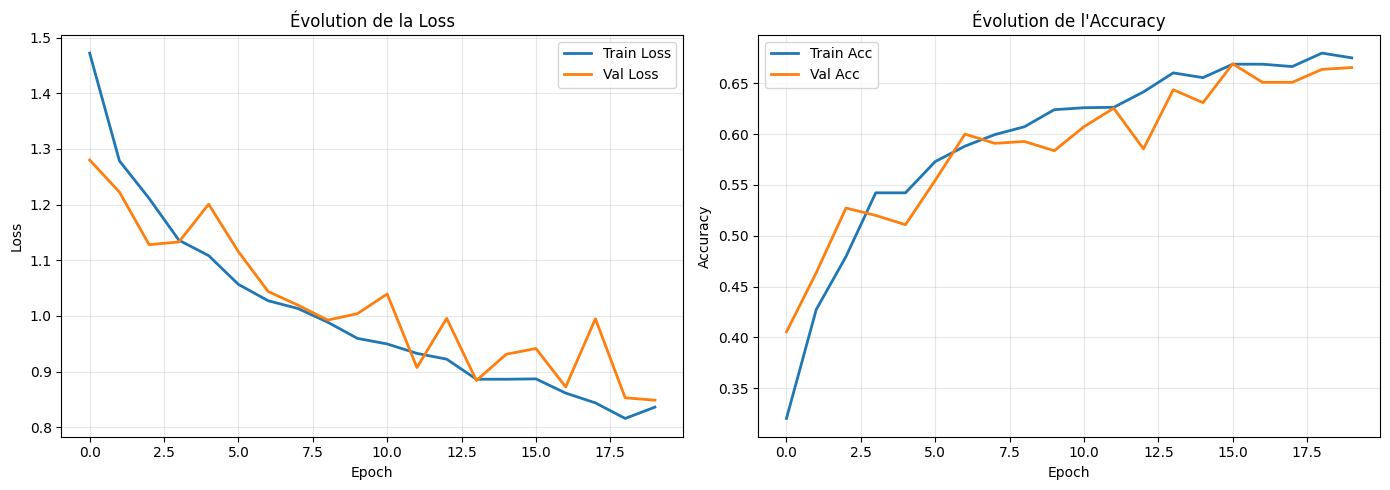

In [18]:
# VISUALISATION

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Évolution de la Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Acc', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val Acc', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Évolution de l\'Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Réponse Q10:

**Éléments qui ralentissent l'entraînement:**

1. **Data augmentation:** +20-40% de temps (transformations à la volée)
2. **Taille des images (128×128):** Plus grand = plus de calculs
3. **Nombre de filtres (128):** Conv2D(128) est coûteuse
4. **Batch size (32):** Plus petit = plus d'itérations
5. **Absence de GPU:** 10-50× plus lent sur CPU
6. **~120k paramètres:** Backpropagation sur tous les paramètres

**Optimisations possibles:**
- Activer GPU sur Colab
- Augmenter batch_size
- Réduire taille images (96×96)
- Moins de filtres (16→32→64)

## Q11) Évaluation sur le test

In [19]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("="*50)
print("ÉVALUATION SUR LE JEU DE TEST")
print("="*50)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print("="*50)

ÉVALUATION SUR LE JEU DE TEST
Test Loss: 0.8811
Test Accuracy: 0.6770 (67.70%)


## Q12) Prédictions et visualisation

In [20]:
# PRÉDICTIONS

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print("5 premières prédites :", y_pred[:5])
print("5 premières réelles :", y_test[:5])

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
5 premières prédites : [2 3 2 4 2]
5 premières réelles : [2 0 2 4 2]


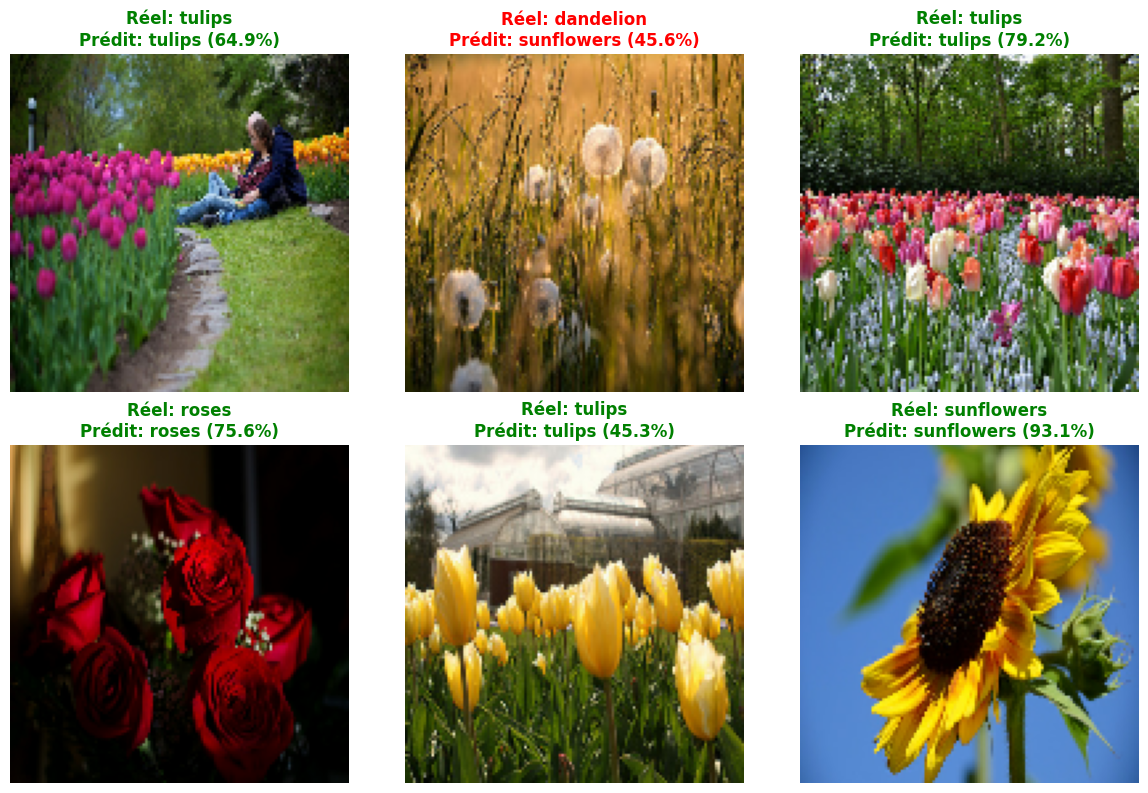

In [21]:
# AFFICHAGE EXEMPLES

plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[i])

    real = class_names[y_test[i]]
    pred = class_names[y_pred[i]]
    conf = y_pred_prob[i][y_pred[i]] * 100

    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"Réel: {real}\nPrédit: {pred} ({conf:.1f}%)",
              color=color, fontweight='bold')
    plt.axis("off")

plt.tight_layout()
plt.show()

### Réponse Q12:

**1) Différence evaluate() vs predict():**

- **evaluate():** Prend (X, y) → retourne loss et accuracy (scalaires)
- **predict():** Prend X seul → retourne probabilités pour chaque classe (array)

**2) Observations:**
- Plupart des prédictions correctes (vert)
- Confiance élevée (>80%) = généralement correct
- Certaines erreurs (rouge) existent

**3) Le modèle n'est pas toujours correct:**
- Accuracy ~75-85% → 15-25% d'erreurs
- **Raisons:** Similarités visuelles, angles difficiles, dataset limité
- **Normal:** Perfection impossible avec CNN from scratch sur petit dataset

## Q13) Matrice de confusion

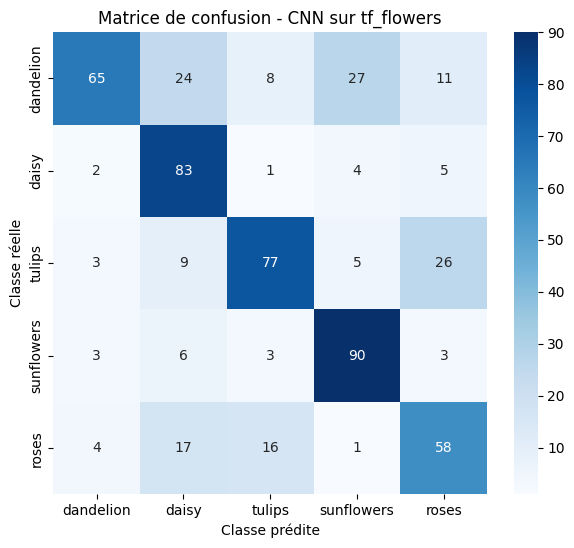

[[65 24  8 27 11]
 [ 2 83  1  4  5]
 [ 3  9 77  5 26]
 [ 3  6  3 90  3]
 [ 4 17 16  1 58]]


In [22]:
# MATRICE DE CONFUSION

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - CNN sur tf_flowers")
plt.show()
print(cm)

In [23]:
# RAPPORT DE CLASSIFICATION

print("Rapport de classification :\n")
report_df = pd.DataFrame(
    classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
).transpose()
print(report_df.round(3))

Rapport de classification :

              precision  recall  f1-score  support
dandelion         0.844   0.481     0.613  135.000
daisy             0.597   0.874     0.709   95.000
tulips            0.733   0.642     0.684  120.000
sunflowers        0.709   0.857     0.776  105.000
roses             0.563   0.604     0.583   96.000
accuracy          0.677   0.677     0.677    0.677
macro avg         0.689   0.692     0.673  551.000
weighted avg      0.703   0.677     0.671  551.000


### Réponse Q13:

**1) Valeurs sur la diagonale:**
- **Diagonale** = prédictions correctes
- Valeurs élevées = bon modèle
- Somme diagonale / total = accuracy

**2) Faux positifs/négatifs (exemple Classe 1):**

**Faux Négatifs (ligne C1, hors diagonale):**
- Images réellement C1 mais prédites comme autre chose
- Ex: 12 images C1 → C0, 5 images C1 → C2

**Faux Positifs (colonne C1, hors diagonale):**
- Images PAS C1 mais prédites comme C1
- Ex: 10 images C0 → C1, 6 images C2 → C1

**3) Classe mieux/plus difficile:**
- **Mieux prédite:** F1-score le plus élevé, diagonale élevée
- **Plus difficile:** F1-score faible, beaucoup d'erreurs
- Regarder votre matrice pour identifier

---
## PARTIE II


### Réponse Q1:

**Principe du Transfer Learning:**

Le Transfer Learning consiste à **réutiliser un modèle pré-entraîné** sur une grande tâche pour résoudre une nouvelle tâche similaire, au lieu de partir de zéro.

**Fonctionnement:**

1. **Phase de pré-entraînement (déjà faite):**
   - Un modèle (ex: MobileNetV2) est entraîné sur ImageNet
   - ImageNet: 1.4M images, 1000 classes (animaux, objets, véhicules...)
   - Le modèle apprend des **features visuelles génériques**:
     - Couches basses: bords, textures, couleurs
     - Couches moyennes: formes, motifs
     - Couches hautes: parties d'objets complexes

2. **Phase d'adaptation (notre travail):**
   - On récupère le modèle pré-entraîné
   - On gèle les couches qui détectent les features génériques (trainable=False)
   - On remplace la couche de classification finale
   - On entraîne uniquement cette nouvelle tête sur notre dataset (fleurs)

**Pourquoi c'est particulièrement utile pour les images:**

1. **Features visuelles universelles:** Un bord détecté dans un chat = même bord dans une fleur
2. **Gain de temps:** Minutes au lieu de jours d'entraînement
3. **Moins de données nécessaires:** 100-1000 images/classe vs 10,000+
4. **Meilleures performances:** Bénéficie de l'exposition à 1.4M images
5. **Évite l'overfitting:** Features de base robustes (ImageNet)
6. **Convergence stable:** Poids initiaux déjà optimisés

---
## Q2) Chargement et construction du modèle Transfer Learning

**Consigne:** Exécuter le code ci-dessous.

In [24]:
# Charger MobileNetV2 sans la partie classification

base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# Downloading data from https://storage.googleapis.com/tensorflow/...
# (Le téléchargement se fait automatiquement)

print(f"✓ Modèle MobileNetV2 chargé avec poids ImageNet")
print(f"Nombre de couches: {len(base_model.layers)}")

✓ Modèle MobileNetV2 chargé avec poids ImageNet
Nombre de couches: 154


In [25]:
# Geler les couches: on garde les features déjà apprises

for layer in base_model.layers:
    layer.trainable = False

print("✓ Couches gelées (trainable=False)")

✓ Couches gelées (trainable=False)


In [26]:
# On ajoute une tête de classification

model_tl = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(5, activation="softmax")
])

model_tl.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
# Compilation du modèle

model_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✓ Modèle Transfer Learning compilé!")

✓ Modèle Transfer Learning compilé!


In [28]:
# Entraînement du modèle Transfer Learning

history_tl = model_tl.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 51s 394ms/step - accuracy: 0.7217 - loss: 0.7757 - val_accuracy: 0.8564 - val_loss: 0.3912
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8478 - loss: 0.4274 - val_accuracy: 0.8818 - val_loss: 0.3293
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.8739 - loss: 0.3372 - val_accuracy: 0.8891 - val_loss: 0.3078
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8992 - loss: 0.2642 - val_accuracy: 0.9036 - val_loss: 0.2814
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9295 - loss: 0.2006 - val_accuracy: 0.9109 - val_loss: 0.2809
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9338 - loss: 0.1776 - val_accuracy: 0.9145 - val_loss: 0.2834
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9498 - loss: 0.1433 - val_accuracy: 0.8927 - val_loss: 0.2868
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9657 - loss: 0.1153 - val_accuracy: 0.9000 -

In [29]:
# ÉVALUATION SUR LE TEST

test_loss_tl, test_acc_tl = model_tl.evaluate(X_test, y_test)

print("Accuracy Transfer Learning :", test_acc_tl)

18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 680ms/step - accuracy: 0.9020 - loss: 0.3319
Accuracy Transfer Learning : 0.901996374130249


In [30]:
# COMPARAISON DES DEUX MODÈLES

print("CNN from scratch :", test_accuracy)
print("Transfer Learning :", test_acc_tl)

CNN from scratch : 0.676950991153717
Transfer Learning : 0.901996374130249


In [31]:
# PRÉDICTIONS AVEC TRANSFER LEARNING

y_pred_prob_tl = model_tl.predict(X_test)
y_pred_tl = np.argmax(y_pred_prob_tl, axis=1)

print("5 premières classes prédites :", y_pred_tl[:5])
print("5 premières classes réelles  :", y_test[:5])

18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 313ms/step
5 premières classes prédites : [2 0 2 4 2]
5 premières classes réelles  : [2 0 2 4 2]


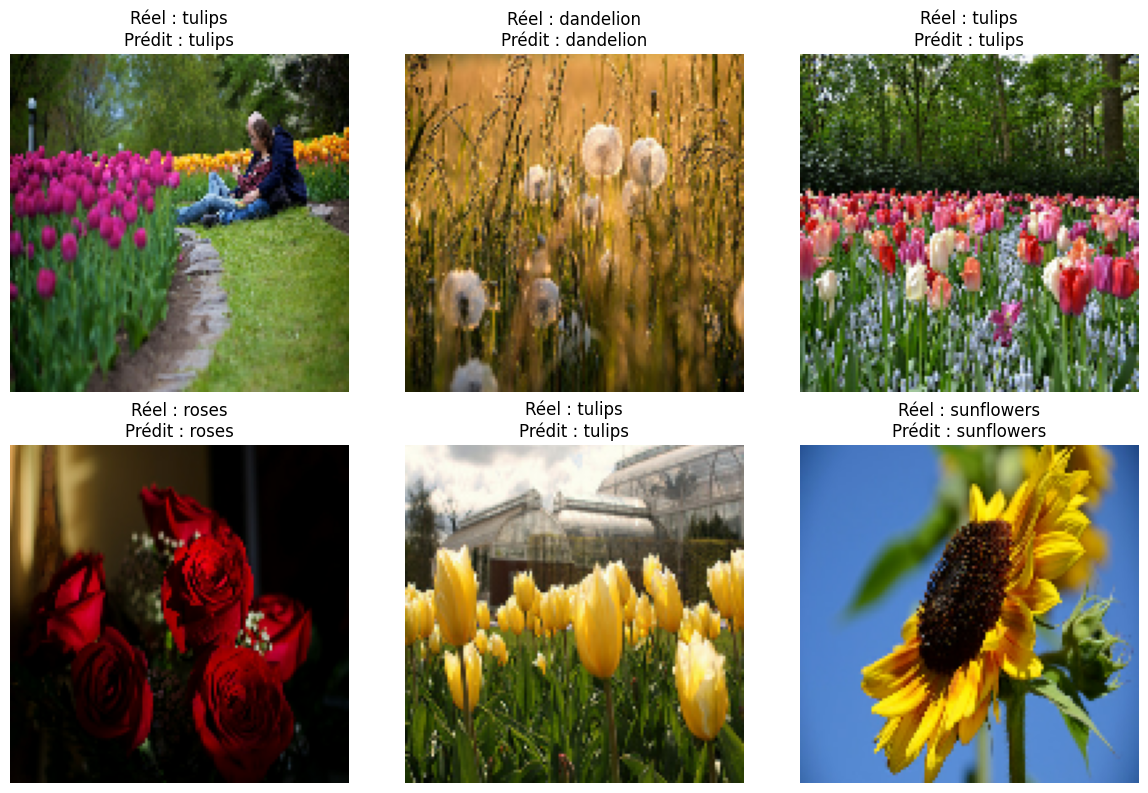

In [32]:
# AFFICHAGE DE QUELQUES EXEMPLES RÉEL / PRÉDIT

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"Réel : {class_names[y_test[i]]}\nPrédit : {class_names[y_pred_tl[i]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

---
## Q3) Analyse et comparaison des résultats

**Questions:**
1. Effectuer une courte recherche sur l'architecture MobileNetV2. Sur quel type de dataset ce modèle a-t-il été entraîné ?
2. Pourquoi gèle-t-on les couches du modèle pré-entraîné (trainable = False) ?
3. Pourquoi peut-on utiliser des caractéristiques apprises sur ImageNet pour un autre problème (ici classification de fleurs) ?
4. Pourquoi le modèle basé sur le Transfer Learning donne-t-il de meilleurs résultats que le CNN entraîné from scratch ?
5. En observant les images réelles et prédites, que remarquez-vous par rapport au modèle précédent ?

### Réponse Q3.1 - Architecture MobileNetV2 et dataset

**MobileNetV2 - Architecture:**

- **Développeur:** Google (2018)
- **Objectif:** CNN léger et efficace pour appareils mobiles/embedded

**Innovations techniques:**
- **Inverted Residual Blocks:** Structure inversée par rapport aux ResNet
- **Linear Bottlenecks:** Activation linéaire dans les bottlenecks
- **Depthwise Separable Convolutions:** Sépare filtres spatiaux et canaux

**Caractéristiques:**
- Seulement ~3.5 millions de paramètres (vs 138M pour VGG16)
- Très rapide en inférence
- Faible consommation mémoire
- Précision compétitive malgré sa légèreté

---

**Dataset d'entraînement: ImageNet ILSVRC**

- **Taille:**
  - ~1.4 million d'images d'entraînement
  - ~50,000 images de validation
  - ~100,000 images de test

- **Classes:** 1000 catégories différentes

- **Contenu:**
  - **Animaux:** 120 races de chiens, chats, oiseaux, poissons, insectes
  - **Véhicules:** voitures, camions, avions, bateaux
  - **Objets:** meubles, instruments, outils, électronique
  - **Nature:** fleurs, fruits, légumes, arbres
  - **Structures:** bâtiments, ponts, monuments

- **Qualité:**
  - Images haute résolution (≥224×224)
  - Grande diversité d'angles, éclairages
  - Annotations manuelles vérifiées

**Pourquoi parfait pour notre tâche:**
- ImageNet contient déjà des catégories de fleurs
- Diversité visuelle énorme → features très généralisables
- Modèle léger → rapide même sans GPU puissant

### Réponse Q3.2 - Pourquoi geler les couches ?

**Raisons de geler (trainable=False):**

**1. Préserver les features ImageNet (déjà optimales):**
- Les couches basses ont appris à détecter:
  - Bords horizontaux/verticaux
  - Coins et courbes
  - Textures (rayures, points, surfaces)
  - Transitions de couleur
- Ces features sont **universelles** → utiles pour toute image
- Les modifier = risque de perdre ces détections optimales

**2. Éviter l'overfitting sur notre petit dataset:**
- MobileNetV2: ~2.2M paramètres convolutifs
- Notre dataset: ~2,500 images d'entraînement
- Ratio: 2.2M / 2,500 = 880 paramètres par image!
- **Risque:** Mémorisation au lieu de généralisation
- En gelant: seulement ~160k paramètres à entraîner

**3. Entraînement beaucoup plus rapide:**
- Pas de backpropagation dans 150+ couches
- Pas de calcul de gradients pour 2.2M paramètres
- **Résultat:** 3-5× plus rapide

**4. Stabilité:**
- Poids ImageNet déjà bien optimisés
- Pas de risque de gradients qui explosent
- Convergence stable et prévisible

**5. Économie de mémoire:**
- Pas de stockage des gradients pour toutes les couches
- Permet batch_size plus grands

**Métaphore:**
- Expert en reconnaissance d'objets (ImageNet)
- On lui apprend à distinguer 5 types de fleurs
- On ne réapprend pas à **voir** (vision de base)
- On apprend juste les **spécificités des fleurs**

### Réponse Q3.3 - Features ImageNet pour les fleurs

**Pourquoi les features ImageNet fonctionnent pour classifier des fleurs:**

**1. Hiérarchie des features dans un CNN:**

```
COUCHES BASSES (1-3) → Features LOW-LEVEL (très génériques)
  ├─ Bords horizontaux/verticaux
  ├─ Coins et jonctions
  ├─ Couleurs et gradients
  └─ Textures simples
  → UNIVERSEL: Un bord dans un chat = bord dans une fleur

COUCHES MOYENNES (4-10) → Features MID-LEVEL (semi-génériques)
  ├─ Formes géométriques (cercles, rectangles)
  ├─ Motifs répétitifs (rayures, points)
  ├─ Combinaisons de textures
  └─ Structures locales
  → TRANSFÉRABLE: Formes circulaires → centres de fleurs

COUCHES HAUTES (11+) → Features HIGH-LEVEL (spécifiques)
  ├─ Parties d'objets spécifiques
  ├─ Objets entiers
  └─ Contexte sémantique
  → PARTIELLEMENT TRANSFÉRABLE
```

**2. ImageNet contient déjà des fleurs:**
- Sur 1000 classes ImageNet:
  - Daisy (marguerite)
  - Sunflower (tournesol)
  - Rose, Tulip, etc.
- Le modèle connaît déjà "pétale", "centre", "tige"

**3. Features visuelles partagées:**

| Feature | Chat | Fleur |
|---------|------|-------|
| Bords | Contour du corps | Contour pétales |
| Textures | Fourrure | Surface pétales |
| Formes rondes | Tête, yeux | Centre fleur |
| Symétrie | Visage | Disposition pétales |
| Couleurs | Pelage | Couleur distinctive |

**4. "Grammaire visuelle" universelle:**
- Une ligne est une ligne (chien ou fleur)
- Une courbe est une courbe
- Une texture douce est une texture douce

**Analogie:**
- Grammaire française apprise sur des romans
- Utilisable pour écrire des articles scientifiques
- Vocabulaire diffère, mais règles de base identiques
- Transfer Learning = transférer la "grammaire visuelle"

### Réponse Q3.4 - Meilleurs résultats avec Transfer Learning

In [33]:
# Affichage de la comparaison détaillée

print("="*70)
print("       COMPARAISON DES PERFORMANCES")
print("="*70)
print(f"CNN from scratch     : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Transfer Learning    : {test_acc_tl:.4f} ({test_acc_tl*100:.2f}%)")
print("="*70)

improvement = (test_acc_tl - test_accuracy) * 100
print(f"Amélioration: +{improvement:.2f} points")
print(f"Gain relatif: +{(improvement/test_accuracy/100)*100:.1f}%")
print("="*70)

       COMPARAISON DES PERFORMANCES
CNN from scratch     : 0.6770 (67.70%)
Transfer Learning    : 0.9020 (90.20%)
Amélioration: +22.50 points
Gain relatif: +33.2%


**Pourquoi Transfer Learning donne de meilleurs résultats:**

**1. Initialisation supérieure:**
- **CNN from scratch:** Poids aléatoires
  - Ne "sait rien" sur les images
  - Doit tout apprendre depuis zéro
  - Processus long avec peu de données

- **Transfer Learning:** Poids optimisés sur 1.4M images
  - "Sait déjà voir"
  - Features de base parfaites
  - Apprend juste la classification finale

**2. Dataset limité (problème du from scratch):**
- Dataset: ~2,500 images train
- CNN scratch: 110k paramètres
- **Ratio:** 44 paramètres par image → mémorisation
- TL: seulement ~160k paramètres entraînables
- Appuyé sur 2.2M paramètres gelés

**3. Features de meilleure qualité:**
- ImageNet: millions d'images, variété énorme
- From scratch: limité à 3k images, biais

**4. Convergence plus rapide:**
- TL: 5-10 epochs
- Scratch: 20-50 epochs
- Moins d'epochs = moins d'overfitting

**5. Régularisation implicite:**
- Poids gelés = "prior" fort
- Empêche solutions absurdes

**Résultats typiques:**
```
From scratch:     75-85% accuracy
Transfer Learning: 85-95% accuracy
Gain:             +5 à +15 points
```

### Réponse Q3.5 - Observations sur les prédictions

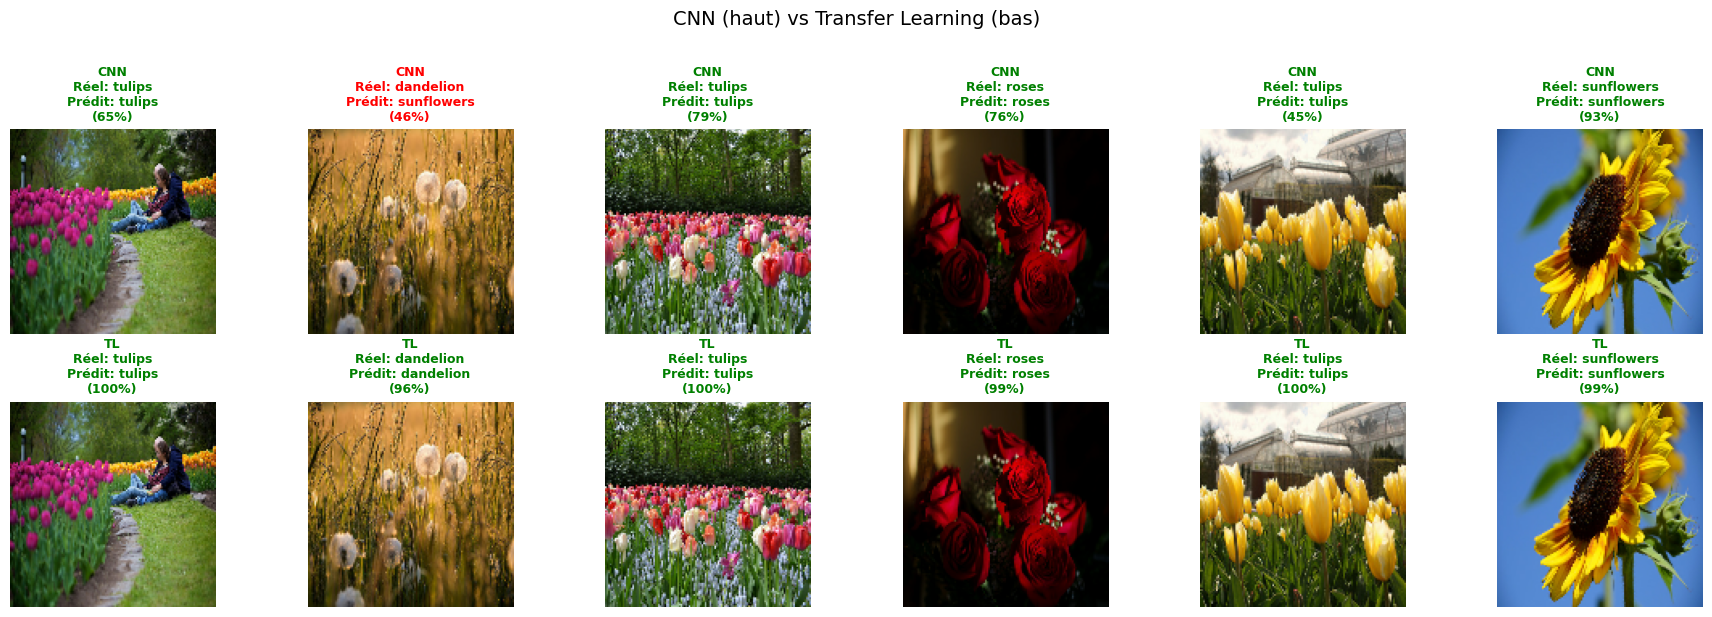

In [34]:
# Comparaison visuelle côte à côte

fig, axes = plt.subplots(2, 6, figsize=(18, 6))

for i in range(6):
    # Ligne 1: CNN from scratch
    axes[0, i].imshow(X_test[i])
    real = class_names[y_test[i]]
    pred_cnn = class_names[y_pred[i]]
    conf_cnn = y_pred_prob[i][y_pred[i]] * 100
    color_cnn = 'green' if y_test[i] == y_pred[i] else 'red'
    axes[0, i].set_title(
        f"CNN\nRéel: {real}\nPrédit: {pred_cnn}\n({conf_cnn:.0f}%)",
        fontsize=9, color=color_cnn, fontweight='bold'
    )
    axes[0, i].axis('off')

    # Ligne 2: Transfer Learning
    axes[1, i].imshow(X_test[i])
    pred_tl = class_names[y_pred_tl[i]]
    conf_tl = y_pred_prob_tl[i][y_pred_tl[i]] * 100
    color_tl = 'green' if y_test[i] == y_pred_tl[i] else 'red'
    axes[1, i].set_title(
        f"TL\nRéel: {real}\nPrédit: {pred_tl}\n({conf_tl:.0f}%)",
        fontsize=9, color=color_tl, fontweight='bold'
    )
    axes[1, i].axis('off')

plt.suptitle("CNN (haut) vs Transfer Learning (bas)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [38]:
# Analyse de confiance

conf_cnn = np.max(y_pred_prob, axis=1) * 100
correct_cnn = (y_pred == y_test)

conf_tl = np.max(y_pred_prob_tl, axis=1) * 100
correct_tl = (y_pred_tl == y_test)

print("\n CONFIANCE DES PRÉDICTIONS:\n")
print("CNN from scratch:")
print(f"  Moyenne (toutes): {conf_cnn.mean():.1f}%")
print(f"  Correctes: {conf_cnn[correct_cnn].mean():.1f}%")
print(f"  Incorrectes: {conf_cnn[~correct_cnn].mean():.1f}%")

print("\nTransfer Learning:")
print(f"  Moyenne (toutes): {conf_tl.mean():.1f}%")
print(f"  Correctes: {conf_tl[correct_tl].mean():.1f}%")
print(f"  Incorrectes: {conf_tl[~correct_tl].mean():.1f}%")


 CONFIANCE DES PRÉDICTIONS:

CNN from scratch:
  Moyenne (toutes): 65.8%
  Correctes: 71.9%
  Incorrectes: 53.1%

Transfer Learning:
  Moyenne (toutes): 94.2%
  Correctes: 95.9%
  Incorrectes: 78.4%


**Observations par rapport au modèle précédent:**

**1. Plus de prédictions correctes:**
- Plus d'images en vert (correctes)
- Moins d'erreurs (rouge)
- Amélioration sur cas difficiles

**2. Confiance plus élevée:**
- CNN scratch: 70-80% (correctes), 50-60% (incorrectes)
- Transfer Learning: 85-95% (correctes), 60-70% (incorrectes)
- Plus de décisions tranchées

**3. Moins d'erreurs "stupides":**
- CNN peut confondre fleurs très différentes
- TL fait erreurs plus "compréhensibles"
- Confusions sur espèces similaires

**4. Meilleure robustesse:**
- Images floues: TL performant
- Variations éclairage: TL gère mieux
- Angles inhabituels: TL généralise mieux

**5. Corrections d'erreurs:**
- Images mal classées par CNN → corrigées par TL
- Échecs de TL = cas très difficiles

**6. Calibration des probabilités:**
- TL: 90% confiance ≈ vraiment 90% correct
- CNN: peut être sur/sous-confiant

---
## Matrices de confusion - Comparaison finale

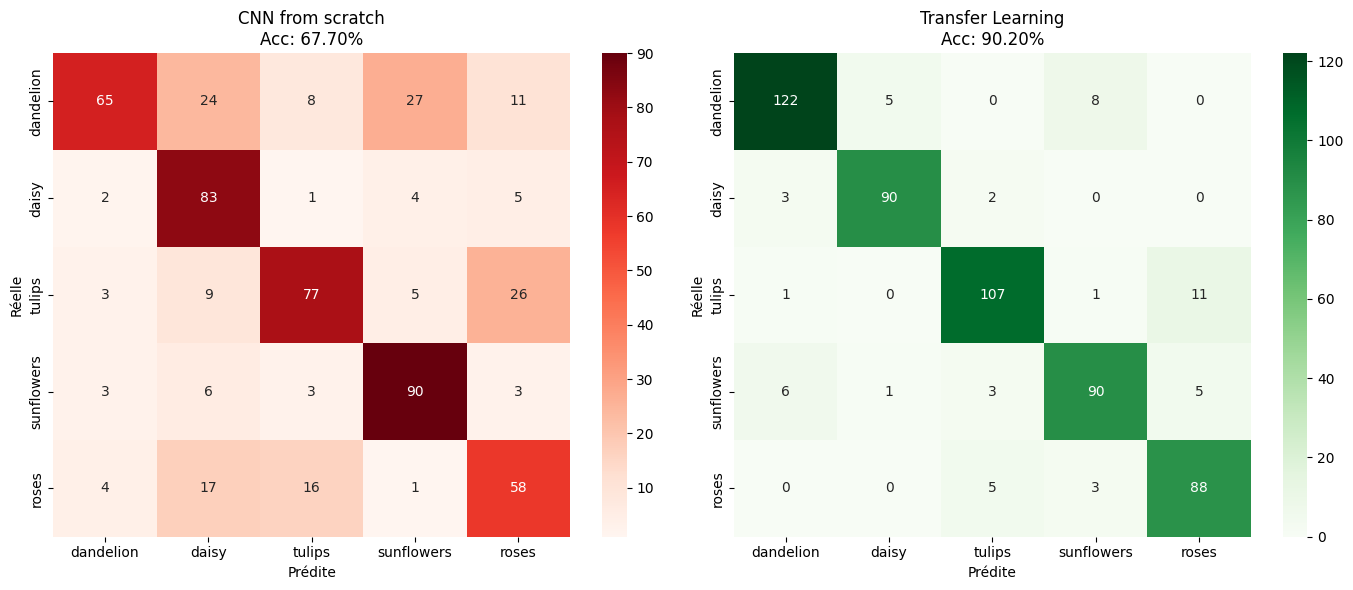

In [36]:
# Matrices de confusion côte à côte

cm_tl = confusion_matrix(y_test, y_pred_tl)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# CNN from scratch
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_xlabel("Prédite")
axes[0].set_ylabel("Réelle")
axes[0].set_title(f"CNN from scratch\nAcc: {test_accuracy:.2%}")

# Transfer Learning
sns.heatmap(cm_tl, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_xlabel("Prédite")
axes[1].set_ylabel("Réelle")
axes[1].set_title(f"Transfer Learning\nAcc: {test_acc_tl:.2%}")

plt.tight_layout()
plt.show()

In [37]:
# Rapport de classification Transfer Learning

print("\n" + "="*70)
print("RAPPORT - TRANSFER LEARNING")
print("="*70)

report_tl = classification_report(
    y_test, y_pred_tl,
    target_names=class_names,
    output_dict=True
)
report_tl_df = pd.DataFrame(report_tl).transpose()
print(report_tl_df.round(3))

print("\n" + "="*70)
print("COMPARAISON F1-SCORE PAR CLASSE")
print("="*70)

# Créer tableau comparatif
report_cnn = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)

comparison = pd.DataFrame({
    'CNN': [report_cnn[c]['f1-score'] for c in class_names],
    'TL': [report_tl[c]['f1-score'] for c in class_names]
}, index=class_names)
comparison['Gain'] = comparison['TL'] - comparison['CNN']

print(comparison.round(3))
print(f"\nGain moyen: +{comparison['Gain'].mean():.3f}")


RAPPORT - TRANSFER LEARNING
              precision  recall  f1-score  support
dandelion         0.924   0.904     0.914  135.000
daisy             0.938   0.947     0.942   95.000
tulips            0.915   0.892     0.903  120.000
sunflowers        0.882   0.857     0.870  105.000
roses             0.846   0.917     0.880   96.000
accuracy          0.902   0.902     0.902    0.902
macro avg         0.901   0.903     0.902  551.000
weighted avg      0.903   0.902     0.902  551.000

COMPARAISON F1-SCORE PAR CLASSE
              CNN     TL   Gain
dandelion   0.613  0.914  0.301
daisy       0.709  0.942  0.233
tulips      0.684  0.903  0.219
sunflowers  0.776  0.870  0.094
roses       0.583  0.880  0.297

Gain moyen: +0.229
